**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: JUNIOR ISRAEL UBRI GONZÁLEZ
*   MATRÍCULA: A01841481

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [27]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [28]:
# Cargar el archivo en el dataframe loan_df
loan_df = pd.read_csv('/content/personal_loan.csv')

# Establecer la columna ID como índice
loan_df.set_index('ID', inplace=True)

# Visualizar los primeros 5 registros
loan_df.head()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
0,25,1,49,91108,4,1.6,1.0,0,0,Yes,No,0,0
1,45,19,34,90089,3,1.5,1.0,0,No,Yes,No,No,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,No,0
4,35,8,45,91330,4,1.0,2.0,0,0,No,No,0,1


In [29]:
# Mostrar información de las columnas y sus tipos de datos
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


 **¿Cuántas columnas son numéricas y cuántas de texto?**

 El conjunto de datos contiene 13 columnas, de las cuales 8 son numéricas (6 de tipo entero int64 y 2 de tipo decimal float64) y 5 son de texto (object), según los resultados obtenidos mediante el método info() de Pandas.

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [30]:
# Obtener estadísticas descriptivas de las variables numéricas
loan_df.describe()

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000,5037.000000
mean,45.411356,20.122494,73.898352,93152.865595,2.394679,1.942404,1.880941,56.500695
std,11.646805,11.461278,46.130504,2119.637960,1.151145,1.755954,0.843337,101.657580
min,23.000000,-3.000000,8.000000,9307.000000,-3.000000,0.000000,1.000000,0.000000
25%,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000
50%,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000
75%,55.000000,30.000000,98.000000,94608.000000,3.000000,2.600000,3.000000,101.000000
max,144.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,7.300000,635.000000


In [31]:
# Filtrar registros con edades superiores a 100 años
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [32]:
# Estadísticas descriptivas de las variables numéricas
loan_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,5037.0,45.411356,11.646805,23.0,35.0,45.0,55.0,144.0
Experience,5037.0,20.122494,11.461278,-3.0,10.0,20.0,30.0,43.0
Income,5037.0,73.898352,46.130504,8.0,39.0,64.0,98.0,224.0
ZIP Code,5037.0,93152.865595,2119.637960,9307.0,91911.0,93437.0,94608.0,96651.0
Family,5037.0,2.394679,1.151145,-3.0,1.0,2.0,3.0,4.0
CCAvg,5037.0,1.942404,1.755954,0.0,0.7,1.5,2.6,10.0
Education,5037.0,1.880941,0.843337,1.0,1.0,2.0,3.0,7.3
Mortgage,5037.0,56.500695,101.657580,0.0,0.0,0.0,101.0,635.0


In [33]:
# Identificar registros con posibles inconsistencias
registros_invalidos = loan_df[
    (loan_df['Age'] < 0) |
    (loan_df['Age'] > 100) |
    (loan_df['Experience'] < 0) |
    (loan_df['Experience'] > loan_df['Age']) |
    (loan_df['Income'] < 0) |
    (loan_df['Family'] < 1) |
    (loan_df['CCAvg'] < 0) |
    (~loan_df['Education'].isin([1, 2, 3])) |
    (loan_df['Mortgage'] < 0)
]

# Mostrar cantidad y registros identificados
print("Registros inconsistentes:", len(registros_invalidos))
display(registros_invalidos)

Registros inconsistentes: 59


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.40,3.0,0,0,0,0,No,0
15,60,30,22,95054,-1,1.50,3.0,0,0,No,0,Yes,Yes
89,25,-1,113,94303,4,2.30,3.0,0,No,No,0,No,Yes
226,24,-1,39,94085,2,1.70,2.0,0,0,No,0,No,0
250,144,6,29,94305,3,1.00,2.0,117,0,No,0,No,No
315,24,-2,51,90630,3,0.30,3.0,0,0,No,No,1,0
347,25,0,43,94305,2,1.60,7.3,0,0,Yes,Yes,1,Yes
451,28,-2,48,94132,2,1.75,3.0,89,0,No,0,1,No
524,24,-1,75,93014,4,0.20,1.0,0,0,No,No,Yes,0


In [34]:
# Eliminar registros inconsistentes
loan_df = loan_df.drop(index=registros_invalidos.index).copy()

# Verificar registros restantes
print("Registros restantes:", len(loan_df))

Registros restantes: 4978


In [35]:
print("Registros con posibles inconsistencias:",
      len(registros_invalidos))

Registros con posibles inconsistencias: 59


**¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?**

El dataframe inicial contenía 5,037 registros y, después del proceso de revisión, se mantuvo la misma cantidad, por lo que no se eliminó ningún registro (0.00%). Esto indica que no se realizaron eliminaciones sobre el conjunto de datos hasta este punto. Sin embargo, es necesario confirmar que se hayan aplicado todos los criterios de limpieza antes de concluir que los registros están libres de inconsistencias.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [36]:
# Estadísticas descriptivas de las variables de texto
loan_df.describe(include='object')

# Frecuencias de cada categoría
for col in loan_df.select_dtypes(include='object'):
    print(f"\n{col}:")
    print(loan_df[col].value_counts())


Personal Loan:
Personal Loan
0      3475
No     1018
Yes     368
1       117
Name: count, dtype: int64

Securities Account:
Securities Account
No     2693
0      1766
Yes     390
1       129
Name: count, dtype: int64

CD Account:
CD Account
No     2462
0      2213
1       163
Yes     140
Name: count, dtype: int64

Online:
Online
Yes    1700
No     1628
1      1276
0       374
Name: count, dtype: int64

CreditCard:
CreditCard
0      2628
Yes     908
No      885
1       557
Name: count, dtype: int64


In [37]:
# Unificar las variables binarias
bin_cols = ['Personal Loan', 'Securities Account',
            'CD Account', 'Online', 'CreditCard']

for col in bin_cols:
    loan_df[col] = loan_df[col].astype(str).str.strip().replace({
        'Yes': '1', 'No': '0'
    }).astype(int)

# Verificar los resultados
print(loan_df[bin_cols].dtypes)

Personal Loan         int64
Securities Account    int64
CD Account            int64
Online                int64
CreditCard            int64
dtype: object


4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [38]:
# Verificar registros duplicados
print("Registros duplicados:", loan_df.duplicated().sum())

# Eliminar registros duplicados
loan_df.drop_duplicates(inplace=True)

# Reiniciar el índice
loan_df.reset_index(drop=True, inplace=True)

# Verificar registros restantes
print("Registros restantes:", len(loan_df))

# Visualizar el dataframe
loan_df.head()

Registros duplicados: 36
Registros restantes: 4942


,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,91108,4,1.6,1.0,0,0,1,0,0,0
1,45,19,34,90089,3,1.5,1.0,0,0,1,0,0,0
2,39,15,11,94720,1,1.0,1.0,0,0,0,0,0,0
3,35,9,100,94112,1,2.7,2.0,0,0,0,0,0,0
4,35,8,45,91330,4,1.0,2.0,0,0,0,0,0,1


5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [39]:
# Convertir ZIP Code a variable nominal
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype('object')

# Convertir Education a categoría ordinal
loan_df['Education'] = pd.Categorical(
    loan_df['Education'],
    categories=[1, 2, 3],
    ordered=True
)

# Convertir variables binarias a categóricas
bin_cols = ['Personal Loan', 'Securities Account',
            'CD Account', 'Online', 'CreditCard']

loan_df[bin_cols] = loan_df[bin_cols].astype('category')

# Crear listas de variables numéricas y categóricas
num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()

# Mostrar las listas
print("num_cols:", num_cols)
print("cat_cols:", cat_cols)

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [40]:
# Estadísticas descriptivas de las variables numéricas
estadisticas = loan_df[num_cols].describe().T

# Agregar asimetría y curtosis
estadisticas['Asimetría'] = loan_df[num_cols].skew()
estadisticas['Curtosis'] = loan_df[num_cols].kurt()

# Mostrar resultados
estadisticas

,count,mean,std,min,25%,50%,75%,max,Asimetría,Curtosis
Age,4942.0,45.561311,11.314736,24.0,36.0,46.0,55.0,67.0,-0.023024,-1.161379
Experience,4942.0,20.336301,11.307402,0.0,11.0,20.0,30.0,43.0,-0.015453,-1.134596
Income,4942.0,73.815864,46.108226,8.0,39.0,64.0,98.0,224.0,0.842132,-0.046006
Family,4942.0,2.391947,1.148356,1.0,1.0,2.0,3.0,4.0,0.159089,-1.404189
CCAvg,4942.0,1.935585,1.748332,0.0,0.7,1.5,2.6,10.0,1.594922,2.636409
Mortgage,4942.0,56.652165,101.868229,0.0,0.0,0.0,101.0,635.0,2.104183,4.761586


7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

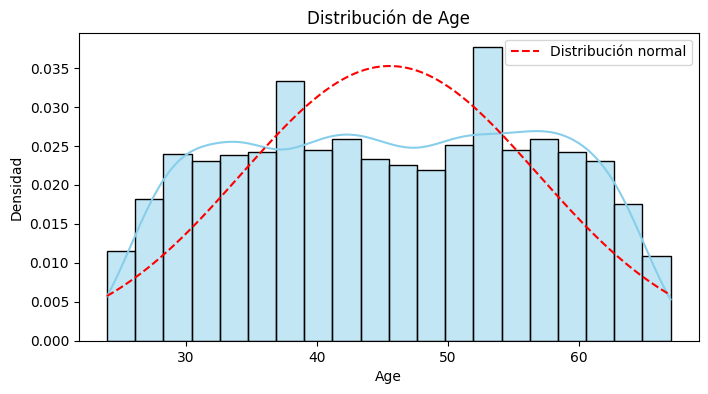

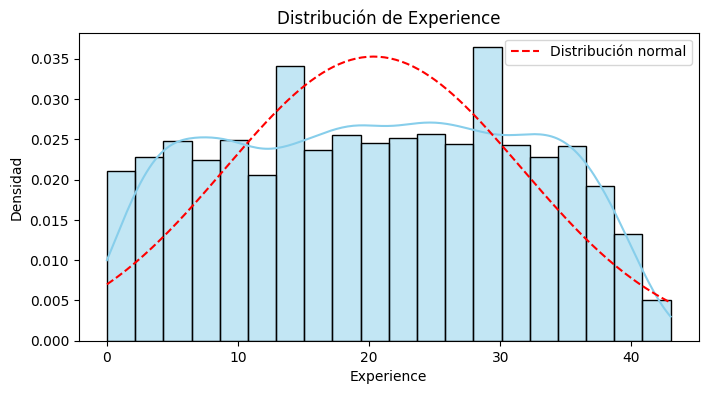

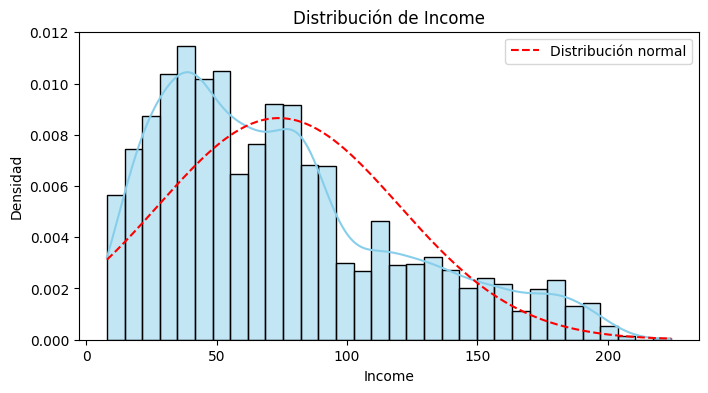

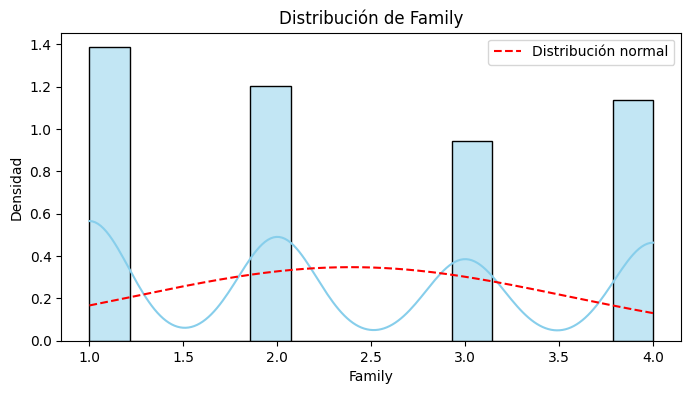

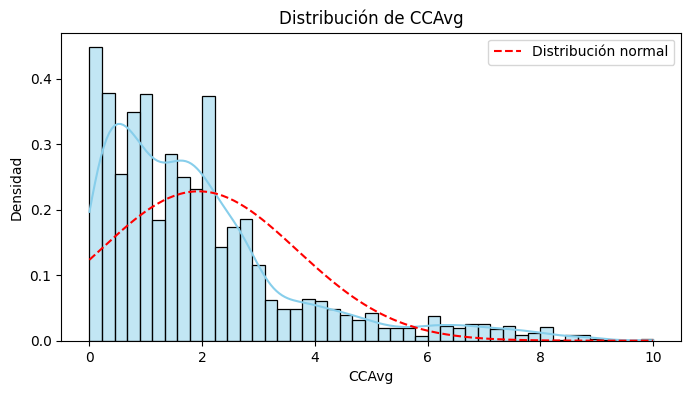

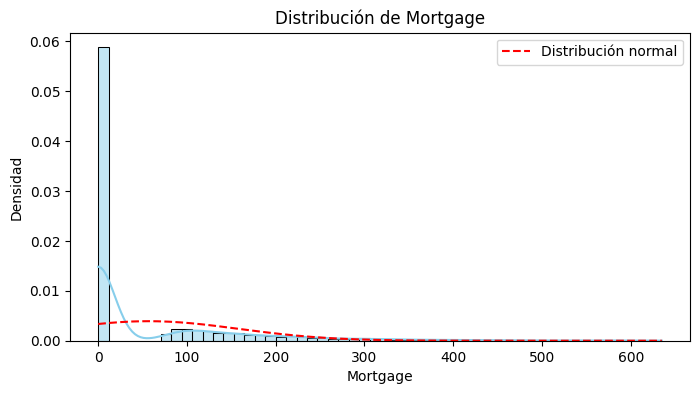

In [41]:
# Histogramas con KDE y distribución normal
for col in num_cols:
    datos = loan_df[col].dropna()

    plt.figure(figsize=(8, 4))

    # Histograma y curva KDE
    sns.histplot(datos, kde=True, stat='density',
                 color='skyblue', alpha=0.5)

    # Curva de distribución normal
    x = np.linspace(datos.min(), datos.max(), 200)
    plt.plot(x, norm.pdf(x, datos.mean(), datos.std()),
             color='red', linestyle='--', label='Distribución normal')

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Densidad')
    plt.legend()
    plt.show()

**Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.**

Los histogramas muestran resultados coherentes con los valores de asimetría y curtosis calculados anteriormente.

**Age:** Presenta una distribución aproximadamente simétrica (asimetría = 0.2153), con mayor concentración de edades entre 30 y 60 años. Su curtosis positiva (0.7028) indica una distribución leptocúrtica, aunque se observa un valor extremo de 144 años que debe revisarse.

**Income:** Muestra una asimetría positiva moderada (0.8413), con mayor concentración de ingresos bajos y medios y una cola extendida hacia valores elevados. Su curtosis cercana a cero (-0.0442) es consistente con una distribución aproximadamente mesocúrtica.

**Mortgage:** Presenta una asimetría positiva pronunciada (2.1040) y una curtosis elevada (4.7570), lo que coincide con la fuerte concentración de valores en cero y la presencia de una cola larga hacia la derecha.

Las distribuciones observadas coinciden con las medidas estadísticas calculadas, aunque presentan diferencias respecto a una distribución normal.

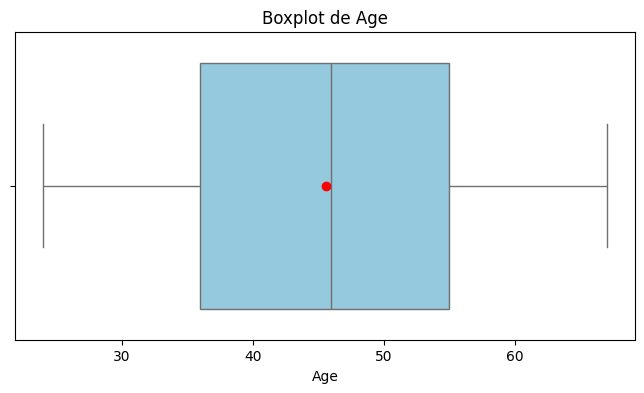

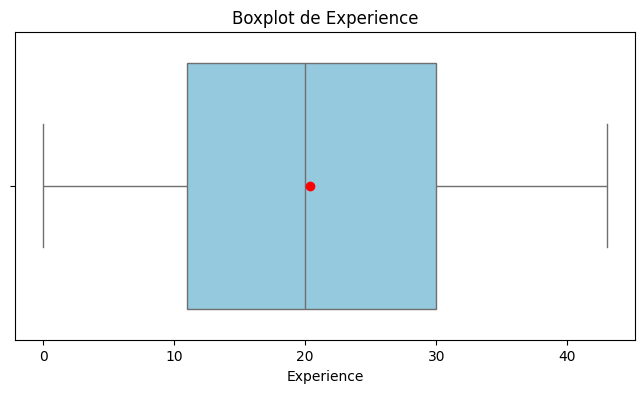

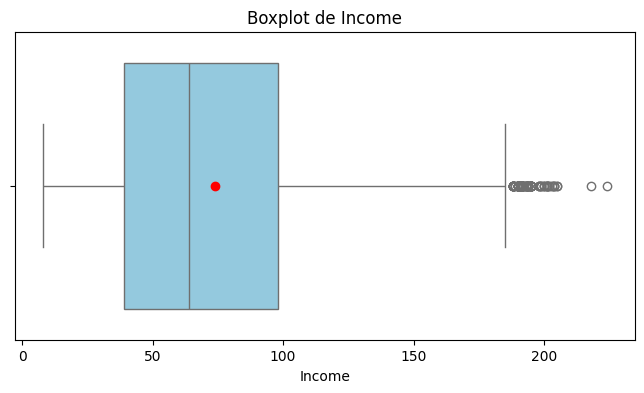

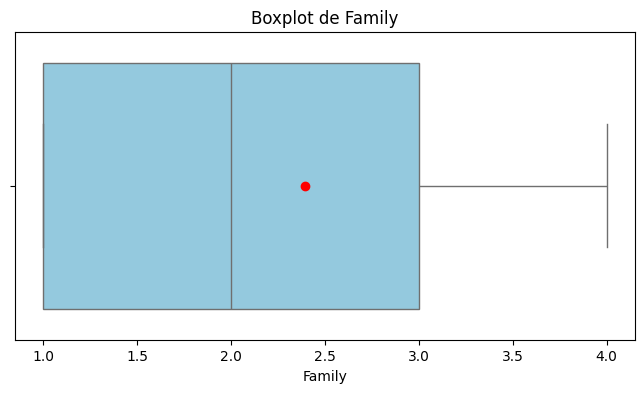

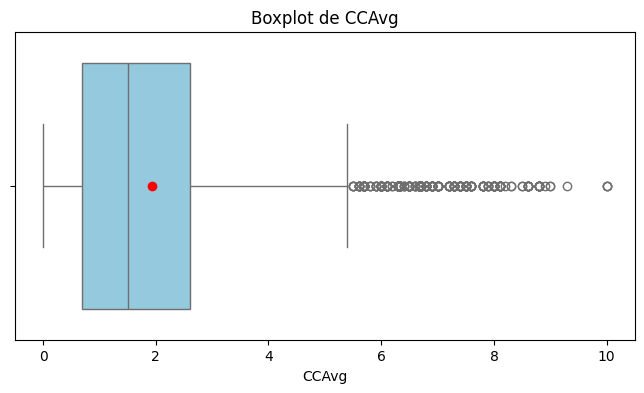

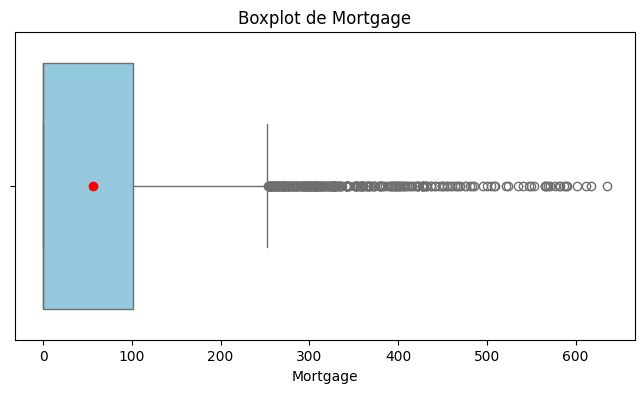

In [42]:
# Generar boxplots individuales con la media
for col in num_cols:
    plt.figure(figsize=(8, 4))

    sns.boxplot(x=loan_df[col], color='skyblue',
                showmeans=True,
                meanprops={'marker': 'o',
                           'markerfacecolor': 'red',
                           'markeredgecolor': 'red'})

    plt.title(f'Boxplot de {col}')
    plt.xlabel(col)
    plt.show()

**Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?**

Los boxplots muestran que Age y Experience presentan medias y medianas muy cercanas, lo que indica distribuciones aproximadamente simétricas. En Income, CCAvg y Mortgage, la media supera a la mediana, evidenciando asimetría positiva, debido a la presencia de valores elevados que desplazan el promedio hacia la derecha. Por su parte, Family presenta una media ligeramente superior a la mediana, aunque su distribución es relativamente equilibrada.

En general, cuando la media es mayor que la mediana, existe una tendencia hacia la asimetría positiva; cuando es menor, puede indicar asimetría negativa. La cercanía entre ambas medidas sugiere una distribución aproximadamente simétrica.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [43]:
# Estadísticas descriptivas de las variables categóricas
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4942,4942,4942,4942,4942,4942,4942
unique,468,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4463,4427,4641,2952,3489


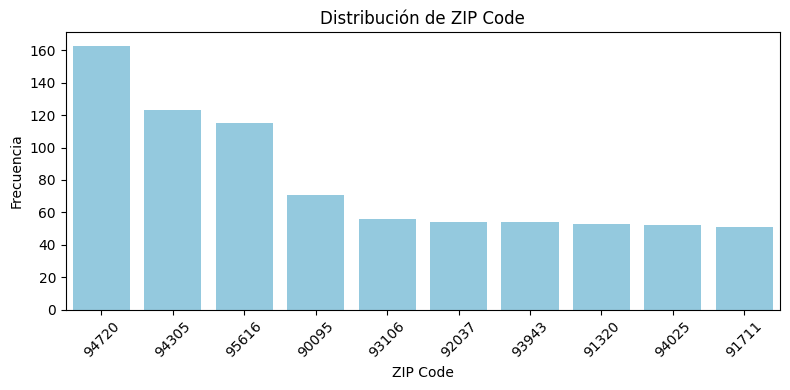

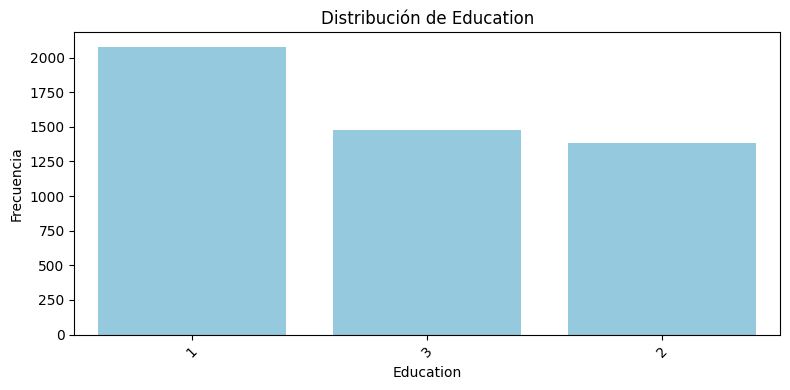

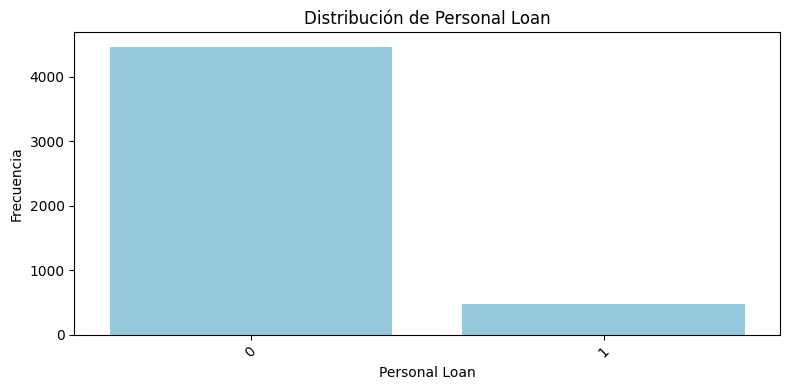

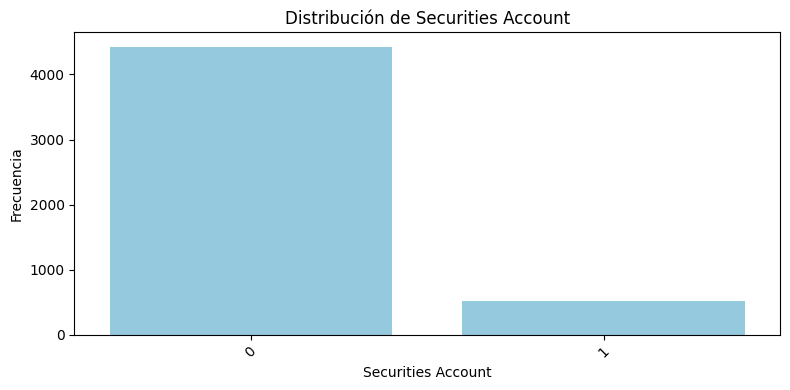

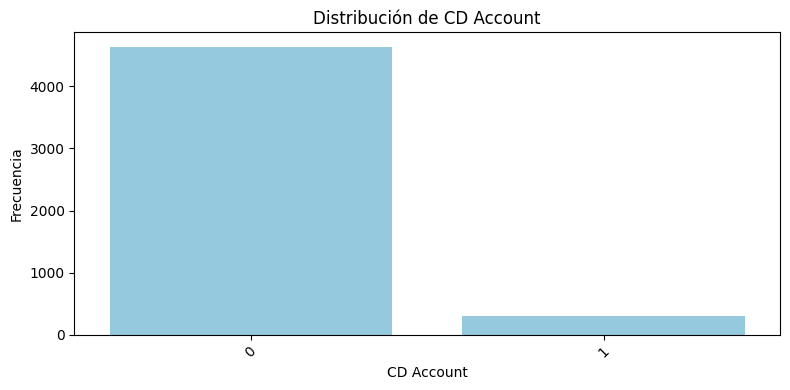

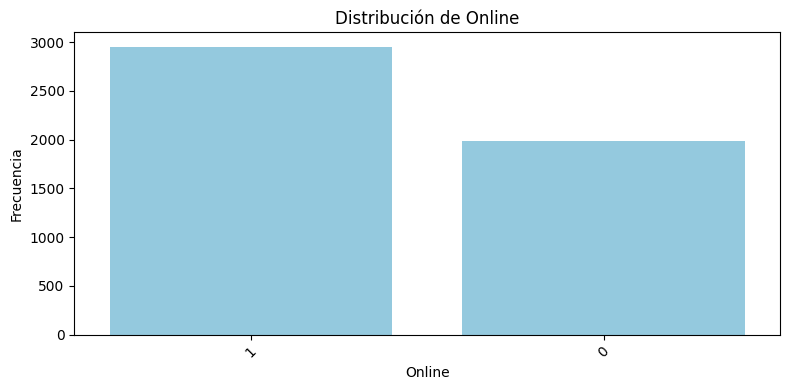

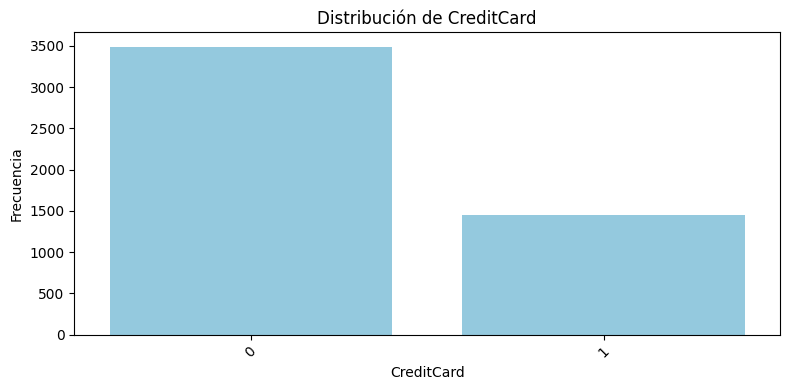

In [44]:
# Gráficos de barras de las variables categóricas
for col in cat_cols:
    frecuencias = loan_df[col].value_counts().head(10)

    plt.figure(figsize=(8, 4))
    sns.barplot(x=frecuencias.index.astype(str),
                y=frecuencias.values,
                color='skyblue')

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

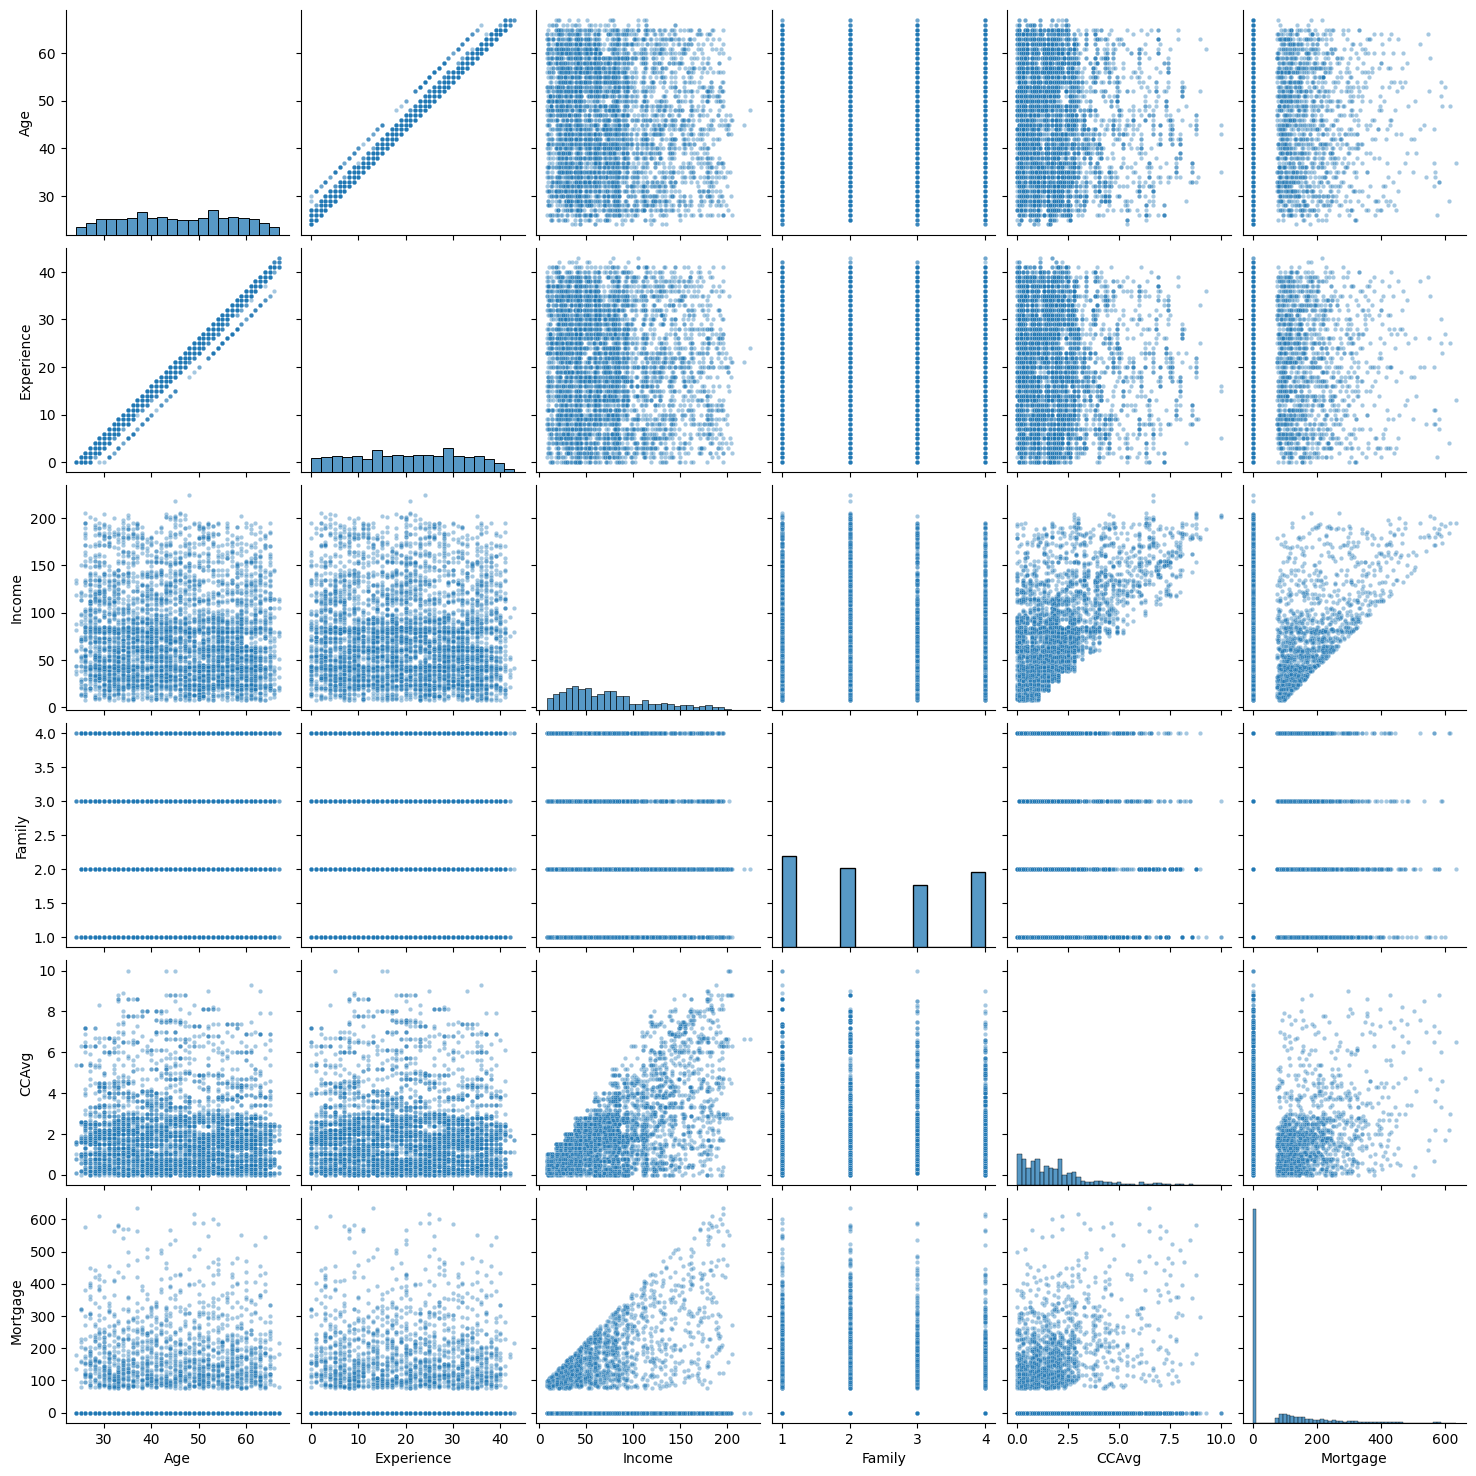

In [45]:
# Matriz de dispersión de las variables numéricas
sns.pairplot(loan_df[num_cols],
             diag_kind='hist',
             plot_kws={'alpha': 0.4, 's': 10})

plt.show()

**Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.**

La matriz de dispersión muestra una relación positiva y aproximadamente lineal entre Age y Experience, indicando que, a medida que aumenta la edad de los clientes, también tienden a incrementarse sus años de experiencia laboral. Asimismo, se observa una relación positiva entre Income y CCAvg, lo que sugiere que los clientes con mayores ingresos tienden a registrar gastos más elevados con tarjeta de crédito.

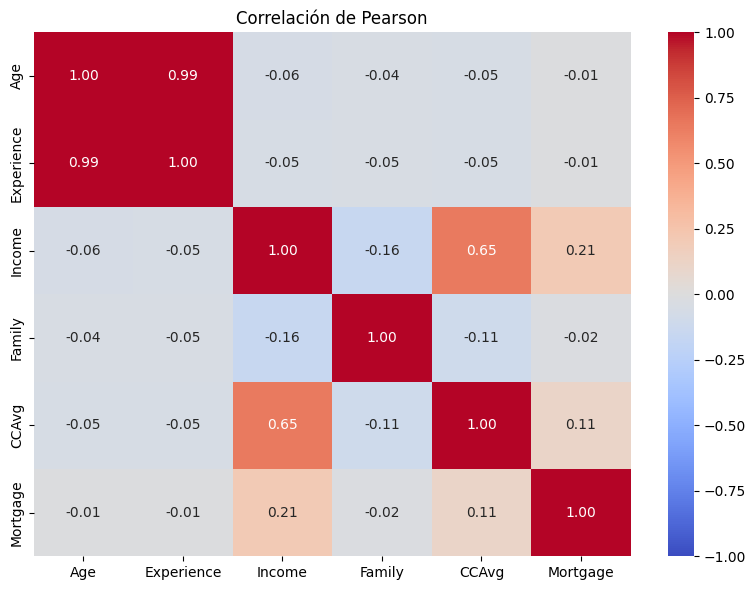

In [46]:
# Calcular correlaciones de Pearson
correlacion = loan_df[num_cols].corr(method='pearson')

# Generar mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, cmap='coolwarm',
            fmt='.2f', vmin=-1, vmax=1)

plt.title('Correlación de Pearson')
plt.tight_layout()
plt.show()

**¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?**

El mapa de calor muestra una correlación positiva muy fuerte entre Age y Experience (r = 0.99), lo que confirma que, a mayor edad, los clientes tienden a presentar más años de experiencia laboral. Este valor numérico sí corresponde con lo esperado, ya que coincide con la relación lineal positiva observada previamente en la matriz de dispersión. Asimismo, Income y CCAvg presentan una correlación positiva moderada (r = 0.65), mientras que las demás variables muestran relaciones débiles.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


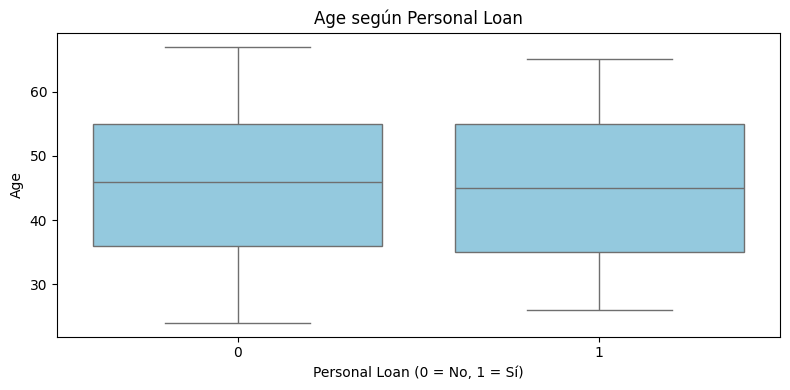

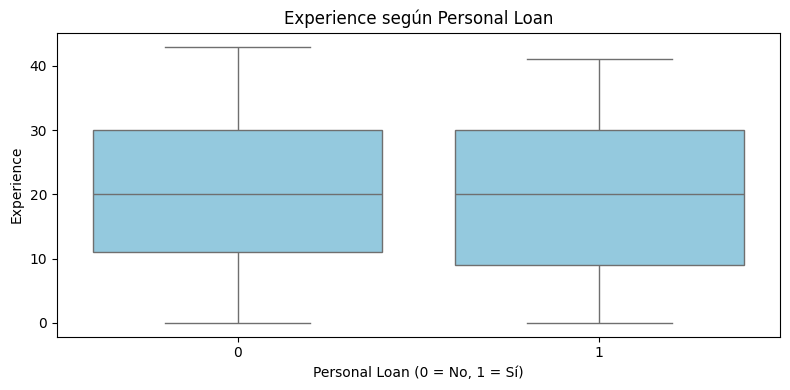

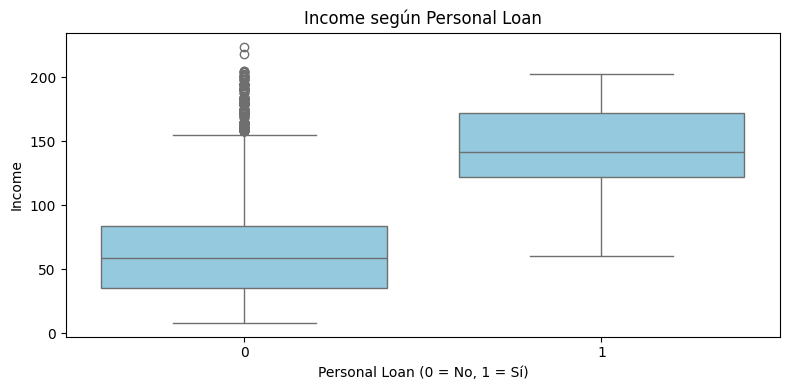

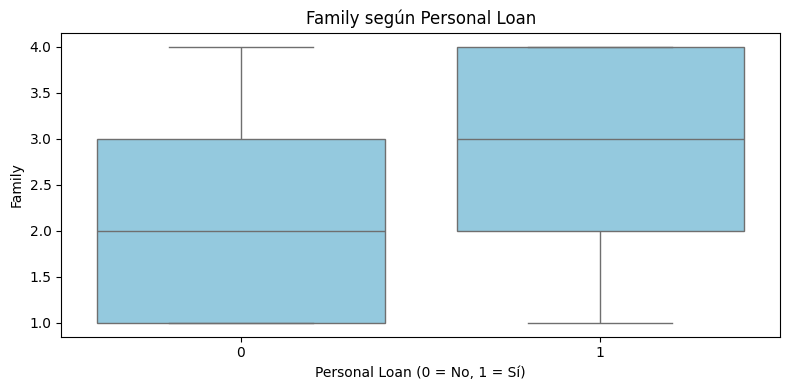

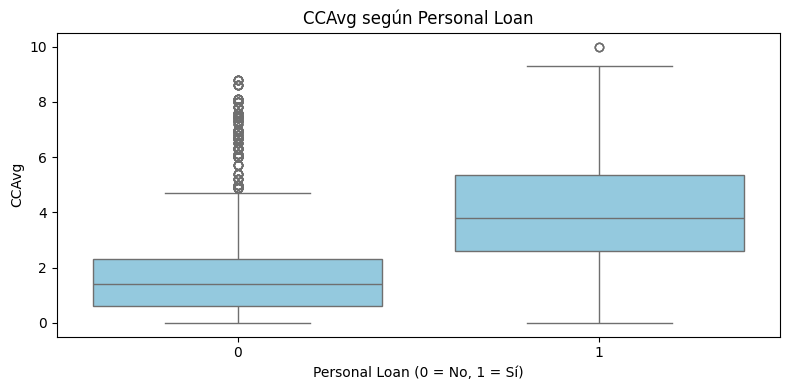

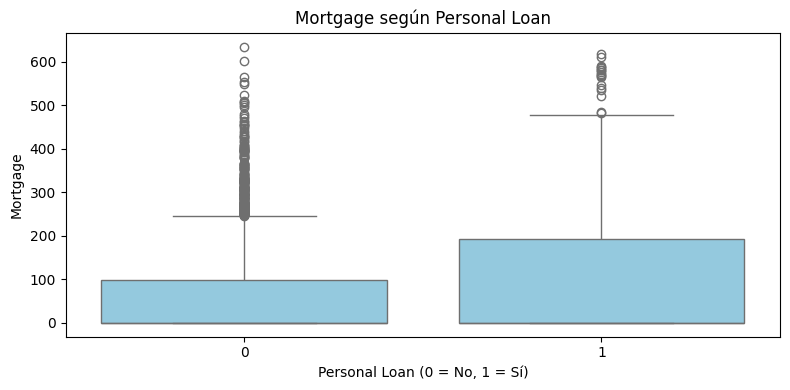

In [47]:
# Boxplots de variables numéricas según Personal Loan
for col in num_cols:
    plt.figure(figsize=(8, 4))

    sns.boxplot(data=loan_df, x='Personal Loan',
                y=col, color='skyblue')

    plt.title(f'{col} según Personal Loan')
    plt.xlabel('Personal Loan (0 = No, 1 = Sí)')
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

Los boxplots muestran que los clientes que aceptaron un préstamo personal presentan ingresos anuales (Income) y gastos mensuales con tarjeta de crédito (CCAvg) considerablemente mayores que quienes no lo aceptaron. Asimismo, se observa una mediana familiar más elevada entre los clientes que aceptaron el préstamo. Por el contrario, Age y Experience presentan distribuciones similares en ambos grupos, por lo que no se evidencian diferencias importantes relacionadas con estas variables. En consecuencia, Income y CCAvg destacan como las variables numéricas con mayores diferencias visuales respecto a la aceptación del préstamo.

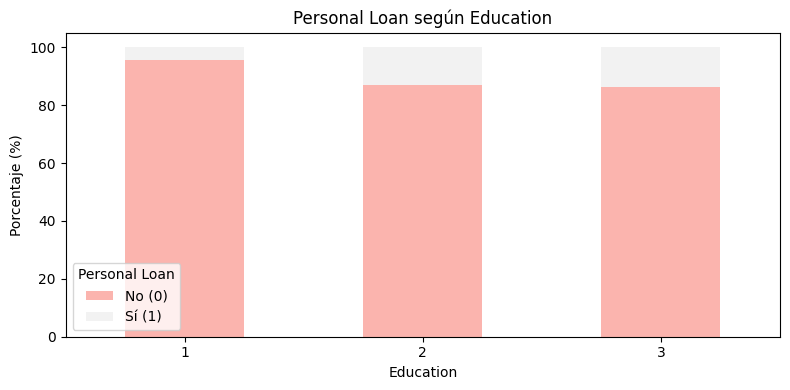

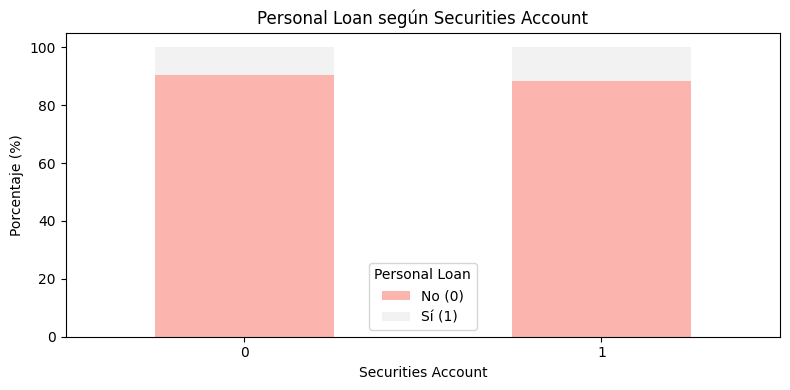

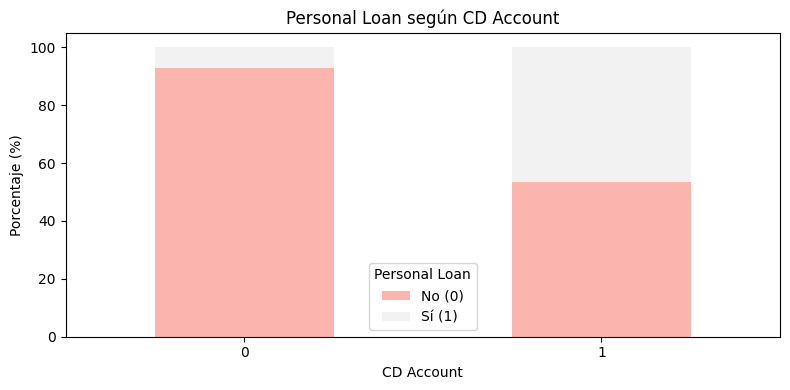

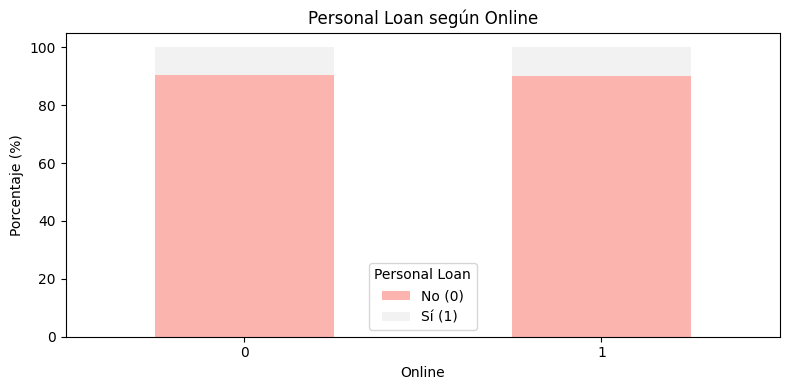

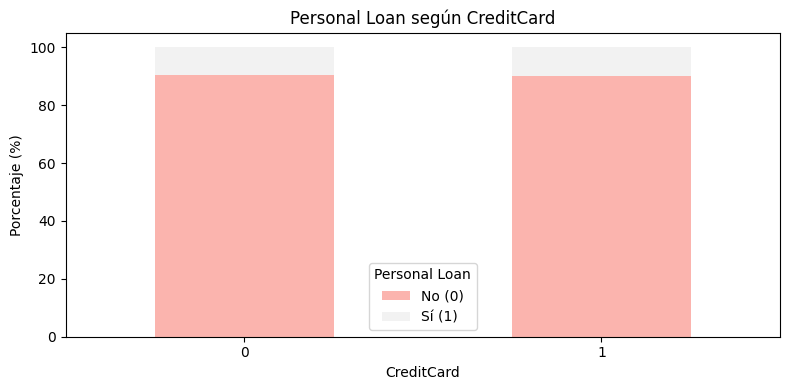

In [48]:
# Variables categóricas a analizar
cat_analisis = [col for col in cat_cols
                if col not in ['ZIP Code', 'Personal Loan']]

# Gráficos de barras apiladas con porcentajes
for col in cat_analisis:
    tabla = pd.crosstab(
        loan_df[col],
        loan_df['Personal Loan'],
        normalize='index'
    ) * 100

    tabla.plot(kind='bar', stacked=True,
               figsize=(8, 4), colormap='Pastel1')

    plt.title(f'Personal Loan según {col}')
    plt.xlabel(col)
    plt.ylabel('Porcentaje (%)')
    plt.legend(title='Personal Loan',
               labels=['No (0)', 'Sí (1)'])
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.

**Hallazgos de las variables numéricas:** Los clientes que aceptaron préstamos personales presentan ingresos anuales (Income) y gastos mensuales con tarjeta de crédito (CCAvg) considerablemente mayores que quienes no los aceptaron. En cambio, Age y Experience muestran distribuciones similares entre ambos grupos.

**Hallazgos de las variables categóricas:** La variable CD Account presenta la diferencia más notable, ya que los clientes con certificados de depósito muestran una mayor proporción de aceptación de préstamos personales. Asimismo, los niveles educativos 2 y 3 registran porcentajes de aceptación superiores al nivel 1, mientras que Online y CreditCard presentan diferencias poco significativas visualmente.

---

**Declaración de uso de IA**

OpenAI. (2026). ChatGPT (basado en GPT-6) [Modelo de lenguaje grande]. Utilizado como herramienta de apoyo para la depuración y corrección de código Python.